In [81]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial import cKDTree


In [82]:
# Parameters
n = 100
dt = 0.01
g = 9.82
gamma = 7
water_depth = 5
reference_density = 1000
speed_of_sound = 200 * g * water_depth * reference_density / gamma
particle_mass = 10
particle_spacing = 0.1
h = 1.3 * particle_spacing

# Viscousity parameters
alpha = 0.01
eta = 0.001

# Boundary parameters
exp1 = 4
exp2 = 2
repulsion_strength = 5 * g * water_depth

In [83]:
def get_neighbors(positions, h):
    tree = cKDTree(positions)
    neighbors = tree.query_ball_point(positions, r=2*h)
    return neighbors


In [84]:
def initalize_particles():
    velocities = np.zeros((n**2, 2))

    x = np.linspace(particle_spacing, n * particle_spacing, n)
    positions = np.array(np.meshgrid(x, x)).T.reshape(-1,2)

    densities = np.ones(n**2) * reference_density

    return positions, velocities, densities

In [85]:
# Start off with simple cubic spline kernel
def kernel(position1, position2):
    r = np.linalg.norm(position1, position2)
    q = r / h
    if q < 1:
        fq = 1 - 3 / 2 * q**2 + 3 / 4 * q**3
    elif q < 2:
        fq = 1 / 4 * (2 - q)**3
    else:
        fq = 0
    W = 10 * fq / (7 * np.pi * h**2)
    return W

def kernel_gradient(position1, position2):
    r = np.linalg.norm(position1 - position2)
    q = r / h
    if q < 1:
        fpq = -3 * q + 9 / 4 * q**2
    elif q < 2:
        fpq = -3 / 4 * (2 - q)**2
    else:
        fpq = 0
    dWdr = 10 * fpq / (7 * np.pi * h**3)
    nabla_W = dWdr * (position1 - position2) / r
    return nabla_W


In [86]:
# Setting beta = 0
def compute_viscous_force(rel_pos, rel_vel, mean_density):
    dotp = np.dot(rel_vel, rel_pos)
    if dotp > 0:
        return 0
    r = np.linalg.norm(rel_pos)
    mu = h * dotp / (r**2 + eta**2)
    return - alpha * speed_of_sound * mu / mean_density

In [ ]:
def compute_boundary_force(particle_position, boundary_positions):
    total_force = np.zeros(2)
    for boundary_position in boundary_positions:
        r_vec = particle_position - boundary_position
        r = np.linalg.norm(r_vec)
        # If far enough away, force is just 0
        if r > particle_spacing:
            return 0
        term1 = (particle_spacing / r)**exp1
        term2 = (particle_spacing / r)**exp2
        force = repulsion_strength * (term1 - term2) * r_vec / (r**2)
        total_force += force
    return force

In [ ]:
def compute_density_change(positions, velocities, neighbors):
    densities_changes = np.zeros(len(neighbors))
    # print("neigbors_length: ", len(neighbors))
    for particle_index, particle_neighbors in enumerate(neighbors):
        # print("particle_index: ", particle_index, "neighbors: ", particle_neighbors)
        for neighbor_index in particle_neighbors:
            if particle_index == neighbor_index:
                continue
            velocity_dir = velocities[particle_index] - velocities[neighbor_index]
            nabla_W = kernel_gradient(positions[particle_index], positions[neighbor_index])
            densities_changes[particle_index] += particle_mass * np.dot(velocity_dir, nabla_W)
    return densities_changes

def compute_pressure(densities):
    pressures = speed_of_sound * ((densities / reference_density)**gamma - 1)
    return pressures

def compute_acceleration(positions, velocities, densities, pressures, neighbors, boundary_positions):
    number_of_particles = len(densities)
    # Initalize accelrations with graivty
    accelerations = np.array([np.array([0, -g]) for _ in range(number_of_particles)])
    for particle_index, particle_neigbors in enumerate(neighbors):
        for neighbor_index in particle_neigbors:
            if particle_index == neighbor_index:
                continue
            p1 = pressures[particle_index] / (densities[particle_index]**2)
            p2 = pressures[neighbor_index] / (densities[neighbor_index]**2)

            rel_pos = positions[particle_index] - positions[neighbor_index]
            rel_vel = velocities[particle_index] - velocities[neighbor_index]
            mean_density = np.mean([densities[particle_index], densities[neighbor_index]])
            viscous_force = compute_viscous_force(rel_pos, rel_vel, mean_density)

            nabla_W = kernel_gradient(positions[particle_index], positions[neighbor_index])

            total = particle_mass * (p1 + p2 + viscous_force) * nabla_W
            accelerations[particle_index] += total
        boundary_force = compute_boundary_force(positions[particle_index], boundary_positions)
        accelerations[particle_index] += boundary_force
    return accelerations

In [89]:
# very simple method, no midpoint update stuff
def update_particles(positions, velocities, accelerations):
    velocities += accelerations
    positions += velocities

In [90]:
# The boundary is represented by particles as well
def initalize_boundary_particles(width, height):
    x = np.arange(0, width + particle_spacing / 2, particle_spacing)
    y = np.arange(0, height + particle_spacing / 2, particle_spacing)

    bottom = np.column_stack((
        x, np.zeros(len(x))
    ))

    top = np.column_stack((
        x, np.full(len(x), height)
    ))

    left = np.column_stack((
        np.zeros(len(y)), y
    ))

    right = np.column_stack((
        np.full(len(y), width), y
    ))

    boundary_particles = np.vstack((
        bottom, top, left, right
    ))

    # Remove duplicates
    boundary_particles = np.unique(
        boundary_particles,
        axis=0
    )

    return boundary_particles

In [91]:
def update(positions, velocities, densities, boundary_positions):
    print("get_neighbors")
    neighbors = get_neighbors(positions, h)
    print("compute_density_change")
    densities += compute_density_change(positions, velocities, neighbors)
    print("compute_pressure")
    pressures = compute_pressure(densities)
    print("compute_acceleration")
    accelerations = compute_acceleration(positions, velocities, densities, pressures, neighbors, boundary_positions)
    print("update_particles")
    update_particles(positions, velocities, accelerations)
    print("done!")

def draw(positions, boundary_positions):
    plt.scatter(positions[:, 0], positions[:, 1], s=1)
    plt.scatter(boundary_positions[:, 0], boundary_positions[:, 1])
    plt.show()

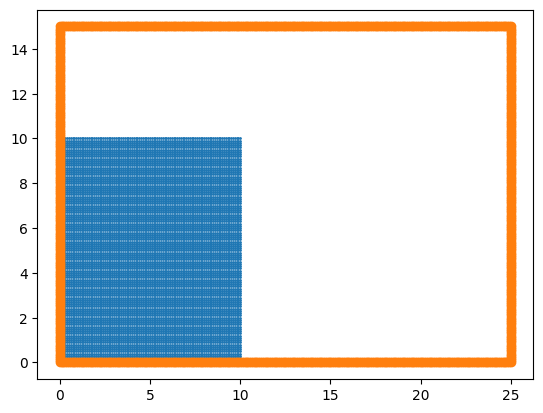

In [92]:
positions, velocities, densities = initalize_particles()
boundary_positions = initalize_boundary_particles(25, 15)

draw(positions, boundary_positions)

In [93]:
update(positions, velocities, densities, boundary_positions)
draw(positions, boundary_positions)

get_neighbors
compute_density_change
compute_pressure
compute_acceleration


UnboundLocalError: cannot access local variable 'boundary_force' where it is not associated with a value